In [ ]:
%reload_ext autoreload
%autoreload 2

import warnings, os, sys
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import numpy as np
import pandas as pd
import swifter
from functools import reduce
from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem import PandasTools
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')
from rdkit.DataStructs import TanimotoSimilarity
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.Chem import Descriptors

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook"
pio.renderers.default_config = {
    "toImageButtonOptions": {"format": "png", "scale": 5}}

sys.path.append(os.path.abspath(".."))
from new_geass import Geass

sys.path.append(os.path.abspath(R"C:\\Users\\Idener\\Sync\\CODE"))
from aiddtools import fingerprint_tools as fpt
clear_output()

In [3]:
# Palettes
#* https://www.molecularecologist.com/2020/04/23/simple-tools-for-mastering-color-in-scientific-figures/
#* https://github.com/OrdnanceSurvey/GeoDataViz-Toolkit/blob/master/Colours/GDV-colour-palettes.json

geodataviz_diverging_1 = ["#045275", "#089099", "#39B185", "#7CCBA2", "#FCDE9C",
                          "#EEB479", "#E88471", "#7C1D6F", "#CF597E", "#9A275A"]
node_colors = {'red': '#d10808', 'yellow': '#ffc32d', 'green': '#009b73'}

## Fragment NP Atlas

Pandas Apply:   0%|          | 0/36454 [00:00<?, ?it/s]

,npaid,compound_id,compound_name,compound_molecular_formula,compound_molecular_weight,compound_accurate_mass,compound_m_plus_h,compound_m_plus_na,compound_inchi,compound_inchikey,...,synonyms_dois,reassignment_dois,synthesis_dois,mibig_ids,gnps_ids,cmmc_ids,npmrd_id,npatlas_url,ROMol,ISOSMILES
0,NPA000001,1,Curvularide C,C19H37NO5,359.507,359.2672,360.2745,382.2564,InChI=1S/C19H37NO5/c1-7-13(3)16(12-21)20-17(23...,BZLIDAVUQDTJQF-HWTFSWDCSA-N,...,[],[],[],[],[],[],NP0009379,https://www.npatlas.org/explore/compounds/NPA0...,,CC[C@@H](O)C[C@H](C)[C@H](O)[C@@](C)(/C=C/C(=O...
1,NPA000002,2,Homopetasinic acid,C24H32O6,416.514,416.2199,417.2272,439.2091,InChI=1S/C24H32O6/c1-14(2)18-13-24(5)16(4)21(1...,MMWCHIIGAIJQMV-DHCANEKFSA-N,...,[],[],[],[],[],[],NP0250242,https://www.npatlas.org/explore/compounds/NPA0...,,C=C(C)[C@@H]1C[C@@]2(C)C(=CC1=O)CC[C@@H](OC(=O...
2,NPA000003,3,A-503083 F,C18H22N4O13,502.389,502.1183,503.1256,525.1075,InChI=1S/C18H22N4O13/c1-31-9-10(11(13(19)26)34...,RNRCUOCMUNIOMZ-UHFFFAOYSA-N,...,[],[],[],['BGC0000288'],[],[],NP0005648,https://www.npatlas.org/explore/compounds/NPA0...,,COC1C(C(OC2OC(C(=O)O)=CC(O)C2O)C(N)=O)OC(n2ccc...
3,NPA000004,4,Aqabamycin E2,C16H11N3O5,325.280,325.0699,326.0772,348.0591,InChI=1S/C16H11N3O5/c20-12-7-6-10(8-11(12)19(2...,NMMDNCZQLOFGES-UHFFFAOYSA-N,...,[],[],[],[],[],[],NP0009185,https://www.npatlas.org/explore/compounds/NPA0...,,O=Nc1[nH]c(O)c(-c2ccccc2)c1-c1ccc(O)c([N+](=O)...
4,NPA000005,5,Hymenopsin A,C22H32O6,392.492,392.2199,393.2272,415.2091,InChI=1S/C22H32O6/c1-18(10-23)6-3-7-19(2)13-9-...,OYLVOLOSQHRPLK-WRXMSMRBSA-N,...,[],[],[],[],[],[],NP0008877,https://www.npatlas.org/explore/compounds/NPA0...,,C[C@@]1(CO)CCC[C@]2(C)[C@H]3C[C@@]45OC4[C@H](O...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36449,NPA036718,36718,Julichrome Q3-3,C38H38O16,750.706,750.2160,751.2233,773.2052,"InChI=1S/C38H38O16/c1-13(51-15(3)39)27-33(5,49...",FCANTWZHYAQEKU-DLUJSSSPSA-N,...,[],"[{'reference_doi': '10.1002/cbdv.202000057', '...",[],[],"['CCMSLIB00000847609%NCGC00180378-02!%1', 'CCM...",[],NaN,https://www.npatlas.org/explore/compounds/NPA0...,,CC(=O)O[C@H](C)[C@H]1[C@@](C)(O)CC(=O)[C@]23O[...
36450,NPA036719,36719,GE81112A,C24H34ClN9O10,644.042,643.2117,644.2190,666.2009,InChI=1S/C24H34ClN9O10/c25-23-29-7-14(33-23)18...,MPRVLYUMDIXCGD-UHFFFAOYSA-N,...,[],[],[],[],[],[],NaN,https://www.npatlas.org/explore/compounds/NPA0...,,NC(=O)OCC(O)CC(NC(=O)C1NCCCC1O)C(=O)NC(Cc1cnc[...
36451,NPA036723,36723,Subvellerolactone C,C17H26O5,310.390,310.1780,311.1853,333.1672,InChI=1S/C17H26O5/c1-5-17(21)12-10(14(19)22-17...,KJKLEJNFKHFYGR-PDROMXSDSA-N,...,[],[],[],[],[],[],NaN,https://www.npatlas.org/explore/compounds/NPA0...,,CC[C@]1(O)OC(=O)C2=C1[C@H](O)[C@@H]1CC(C)(C)C[...
36452,NPA036726,36726,10E-cyclonerotriol,C15H28O3,256.386,256.2038,257.2111,279.1930,"InChI=1S/C15H28O3/c1-11(10-16)6-5-8-15(4,18)13...",QGUPPGVBDCWDSK-BSYVWGKESA-N,...,[],[],[],[],[],[],NaN,https://www.npatlas.org/explore/compounds/NPA0...,,C/C(=C\CC[C@@](C)(O)[C@@H]1CC[C@@](C)(O)[C@H]1...

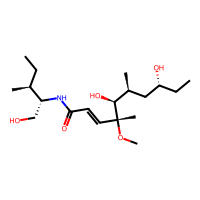
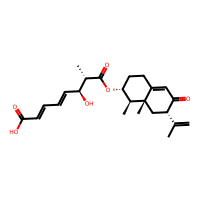
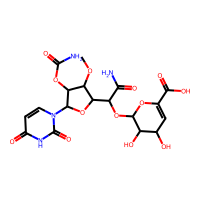
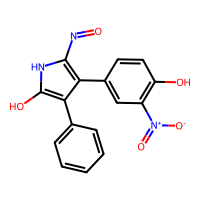
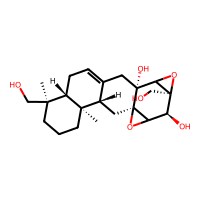
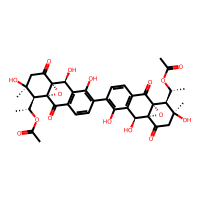
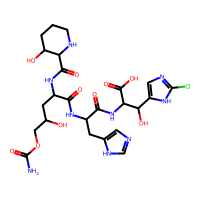
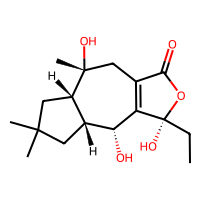
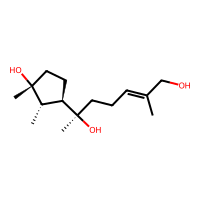
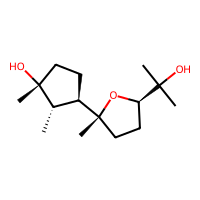

In [ ]:
df_NPA = pd.read_csv('../data/NPAtlas_download_2024_09.tsv', sep='\t')
PandasTools.AddMoleculeColumnToFrame(df_NPA, smilesCol='compound_smiles')
df_NPA['ISOSMILES'] = df_NPA['ROMol'].swifter.apply(Chem.MolToSmiles)

In [ ]:
# Filter out molecules with > 70% atoms in polycyclic rings
df_NPA['N_atoms_polyrings'] = df_NPA['ROMol'].swifter.apply(
    lambda x: len(set().union(*[set(ring) for ring in Chem.GetSymmSSSR(x)])))
df_NPA['N_atoms'] = df_NPA['ROMol'].swifter.apply(lambda x: x.GetNumAtoms())
df_NPA['Percent_atoms_in_rings'] = df_NPA['N_atoms_polyrings'] / df_NPA['N_atoms'] * 100
df_NPA = df_NPA[df_NPA['Percent_atoms_in_rings'] < 70].reset_index(drop=True)

df_NPA = df_NPA[['npaid', 'ISOSMILES', 'ROMol']].rename(columns={'npaid': 'ID'})
filtered_ids = set(df_NPA['ID'].values)

In [ ]:
# Fragment molecules and write to file in batches
df_NPA = pd.read_csv('../data/NPAtlas_download_2024_09.tsv', sep='\t')
PandasTools.AddMoleculeColumnToFrame(df_NPA, smilesCol='compound_smiles')
df_NPA['ISOSMILES'] = df_NPA['ROMol'].swifter.apply(Chem.MolToSmiles)
df_NPA = df_NPA[['npaid', 'ISOSMILES', 'ROMol']].rename(columns={'npaid': 'ID'})

geass = Geass()

fragment_list = []
for row in tqdm(df_NPA.itertuples(), total=df_NPA.shape[0]):
    try:
        fragments = geass.get_fragments(row.ROMol, check_unknowns=False, as_smiles=True)
    except:
        fragments = ['ERROR']
    fragment_list.append(fragments)

df_NPA['Fragments'] = fragment_list
df_NPA = df_NPA[df_NPA['Fragments'].swifter.apply(len) > 1].reset_index(drop=True)

In [ ]:
# Assign ID to fragments

# df_NPA = df_NPA.explode('Fragments').reset_index(drop=True)
df_aux = df_NPA[['Fragments']].drop_duplicates().reset_index(drop=True)
df_aux = df_aux.rename(columns={'Fragments': 'ISOSMILES'})
PandasTools.AddMoleculeColumnToFrame(df_aux, 'ISOSMILES')

geass = Geass()
all_ids, all_prob = [], []
for mol in tqdm(df_aux['ROMol'].tolist()):
    id, prob = geass.check_BUL(mol), 1.0
    if id == "":
        id, prob = geass.find_best_match(mol)
    all_ids.append(id)
    all_prob.append(prob)
df_aux['Frag_IDs'] = all_ids
df_aux['Probability'] = all_prob

df_NPA = pd.merge(df_NPA, df_aux, left_on='Fragments', right_on='ISOSMILES', how='left')
df_NPA = df_NPA.rename(columns={'ISOSMILES_x': 'ISOSMILES'})
df_NPA = df_NPA.drop(columns=['ROMol_x', 'ROMol_y', 'ISOSMILES_y'])
df_NPA.loc[df_NPA['Fragments'] == '*C', 'Frag_IDs'] = '[C00019]'
df_NPA['Probability'] = df_NPA['Probability'].round(2)

df_NPA.to_csv('Database_NPA_fragmented.csv', index=False)
df_NPA.to_pickle('Database_NPA_fragmented.pkl')

## Analysis of fragments

In [72]:
df_NPA = pd.read_pickle('Database_NPA_fragmented.pkl')
df_NPA = df_NPA[df_NPA['ID'].isin(filtered_ids)].reset_index(drop=True)

# Create sequential unknown IDs
mask = df_NPA['Probability'] < 0.85
df_NPA.loc[mask, 'Frag_IDs'] = [f"U{i+1:05d}" for i in range(mask.sum())]

In [ ]:
df_NPA_condensed = df_NPA.groupby('ID').agg({
    'ISOSMILES': 'first', 'Fragments': list,
    'Frag_IDs': list, 'Probability': list,}).reset_index()

# Before similarity search
ids = df_NPA_condensed['Frag_IDs']
all_green_i = ids.apply(lambda x: all(id.startswith(('C', 'L')) for id in x))
some_red_i = ~all_green_i

# After similarity search
all_green_f = all_green_i
some_red_f = ids.apply(lambda x: any(id.startswith('U') for id in x))
green_yellow_f = ~all_green_f & ~some_red_f

df_NPA_condensed

In [ ]:
# --- Prepare data ---
summary_data = {
    'Compound annotation': ['Full (direct)', 'Incomplete',
               'Full (direct)', 'Incomplete', 'Full (direct + sim.)'],
    'Stage': ['Before', 'Before', 'After', 'After', 'After'],
    'Count': [1219, 20595, 1219, 13962, 6633]}
summary_df = pd.DataFrame(summary_data)

# --- Base colours ---
color_map = {
    'Full (direct)': '#009b73',
    'Incomplete': "#ff7f0e",
    'Full (direct + sim.)': '#009b73'}

# --- Create grouped bar chart ---
fig_yellow = px.bar(
    summary_df,
    x='Stage',
    y='Count',
    color='Compound annotation',
    pattern_shape='Compound annotation',
    color_discrete_map=color_map,
    barmode='group',
    text='Count')

# --- Add stripe (pattern) settings ---
for trace in fig_yellow.data:
    if trace.name == 'Full (direct + sim.)':
        # Green bar with yellow stripes
        trace.marker.pattern.shape = "/"
        trace.marker.pattern.fgcolor = "#ffea00"
        trace.marker.pattern.solidity = 0.47
        trace.marker.pattern.size = 16
    else:
        # Solid colour for others (no stripes)
        trace.marker.pattern.shape = ""
        trace.marker.pattern.solidity = 0

# --- Layout styling ---
fig_yellow.update_layout(
    xaxis_title='Annotation Stage',
    yaxis_title='Number of compounds',
    font=dict(family="sans-serif"),
    width=800, height=400)

fig_yellow.show()

print(f"""======= Fragmentation Summary =======

*** Before similarity search ***
Full direct annotations (all green nodes): {all_green_i.sum()}
Incomplete annotations (all red or g+r):    {some_red_i.sum()}
Total compounds:                           {(all_green_i | some_red_i).sum()}

*** After similarity search ***
Full direct annotations (all green nodes):                {all_green_f.sum()}
Full direct + similarity annotations (g+y or all yellow): {green_yellow_f.sum()}
Incomplete annotations (at least one red node):           {some_red_f.sum()} (-{(some_red_i.sum() - some_red_f.sum()) / some_red_i.sum() * 100:.1f}%)
Total compounds:                                          {(all_green_f | green_yellow_f | some_red_f).sum()}
""")

NameError: name 'all_green_i' is not defined

In [ ]:


# Count nodes before and after similarity search
green_initial = df_NPA[df_NPA['Frag_IDs'].str.match(r'^[CL]')]
red_initial   = df_NPA[~df_NPA['Frag_IDs'].str.match(r'^[CL]')]

green_final   = green_initial
yellow_final  = df_NPA[df_NPA['Frag_IDs'].str.match(r'^[~\[]')]
red_final     = df_NPA[df_NPA['Frag_IDs'].str.startswith('U')]

In [71]:
# Prepare data
summary_data = {
    'Node annotation': ['Direct', 'None', 'Direct', 'By similarity', 'None'],
    'Stage': ['Before'] * 2 + ['After'] * 3,
    'Count': [
        len(green_initial),
        len(red_initial),
        len(green_final),
        len(yellow_final),
        len(red_final)]}

summary_df = pd.DataFrame(summary_data)

# Plot grouped bar chart
fig_yellow = px.bar(
    summary_df,
    x='Stage',
    y='Count',
    color='Node annotation',
    barmode='group',
    text='Count',
    color_discrete_map={
        'Direct': '#009b73',
        'By similarity': '#ffc32d',
        'None': '#d10808'})

fig_yellow.update_layout(
    # title='Node annotation',
    xaxis_title='Annotation Stage',
    yaxis_title='Number of nodes',
    font=dict(family="sans-serif"),
    width=800, height=400)

fig_yellow.show()

before_total = len(green_initial) + len(red_initial)
after_total  = len(green_final) + len(yellow_final) + len(red_final)

print(f"""======= Node Summary =======

*** Before similarity search ***
Green nodes: {len(green_initial)}
Red nodes:   {len(red_initial)}
Total nodes: {before_total}

*** After similarity search ***
Green nodes:  {len(green_final)}
Yellow nodes: {len(yellow_final)}
Red nodes:    {len(red_final)} ({(len(red_final) - len(red_initial)) / len(red_initial) * 100:+.1f}%)
Total nodes:  {after_total}
""")

======= Node Summary =======

*** Before similarity search ***
Green nodes: 42929
Red nodes:   43170
Total nodes: 86099

*** After similarity search ***
Green nodes:  42929
Yellow nodes: 28819
Red nodes:    14351 (-66.8%)
Total nodes:  86099



In [132]:
n_atom_list = []
for row in df_NPA_condensed.itertuples():
    aux = []
    for smi in row.Fragments:
        try:
            aux.append(Chem.MolFromSmiles(smi).GetNumAtoms())
        except:
            aux.append(0)
    n_atom_list.append(aux)
df_NPA_condensed['Frag_N_atoms'] = n_atom_list

percent_gy_nodes = []
for row in df_NPA_condensed.itertuples():
    indices = [i for i, id in enumerate(row.Frag_IDs) if not 'U' in id]
    n_atom_red_nodes = sum(row.Frag_N_atoms[i] for i in indices)
    n_atom_compound = sum(row.Frag_N_atoms)
    percent_gy_nodes.append(round(n_atom_red_nodes/n_atom_compound*100, 2))
df_NPA_condensed['Percent_gy_nodes'] = percent_gy_nodes

In [ ]:
# Filter out 0% entries
percentages = df_NPA_condensed[df_NPA_condensed['Percent_gy_nodes'] != 0]['Percent_gy_nodes']

bins = np.linspace(0, 100, 11)  # [0, 10, ..., 100]
bins[-1] += 0.1  # extend last bin to include 100.0
bin_labels = [f"{int(bins[i])}-{int(bins[i+1])}%" for i in range(len(bins) - 1)]

# Bin the values
binned = pd.cut(percentages, bins=bins, labels=bin_labels,
                include_lowest=True, right=False)

# Count frequencies
hist_df = binned.value_counts().sort_index().reset_index()
hist_df.columns = ['Bin', 'Count']
hist_df['Text'] = hist_df['Count'].astype(str)

# Plot
fig_yellow = px.bar(
    hist_df,
    x='Bin',
    y='Count',
    text='Text',
    # title='Coverage of Full (direct + sim.) in compounds',
    labels={'Bin': 'Percentage of annotated atoms', 'Count': 'Compound count'})

fig_yellow.update_layout(
    xaxis_title='Percentage of annotated atoms',
    yaxis_title='Number of compounds',
    font=dict(family="sans-serif"),
    bargap=0.1, width=800, height=400)

fig_yellow.show()

In [169]:
# Remove red nodes (U)
all_ids = df_NPA.loc[~df_NPA['Frag_IDs'].str.startswith('U'), 'Frag_IDs']

# Count frequency and convert to percentage
freq = all_ids.value_counts(normalize=True).reset_index()
freq.columns = ['ID', 'Percent']
freq['Percent'] *= 100

# Add category column
freq['Category'] = freq['ID'].apply(lambda x: 'Green (C)' if x.startswith('C') else 'Yellow (~)')

# Top 25 green
top_green = freq[freq['Category'] == 'Green (C)'].head(25)
fig_green = px.bar(
    top_green,
    x='ID',
    y='Percent',
    color_discrete_sequence=['#009b73'],  # same green as before
    labels={'ID': 'BU', 'Percent': 'Percent occurrence'},
    title='Top 25 Green BUs')

fig_green.update_layout(
    xaxis={'categoryorder': 'total descending'},
    width=900, height=500)

# Top 25 yellow
top_yellow = freq[freq['Category'] == 'Yellow (~)'].head(25)

# Define break limits
cut_low, cut_high = 1.5, top_yellow['Percent'].max() * 1.1

# Create two stacked subplots (shared X)
fig_yellow = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    row_heights=[0.3, 0.7],
    vertical_spacing=0.02)

# Bottom subplot (main range)
fig_yellow.add_bar(
    x=top_yellow['ID'],
    y=top_yellow['Percent'].clip(upper=cut_low),
    marker_color='#ffc32d',
    row=2, col=1)

# Top subplot (compressed upper range)
fig_yellow.add_bar(
    x=top_yellow['ID'],
    y=top_yellow['Percent'].where(top_yellow['Percent'] > cut_low, 0),
    marker_color='#ffc32d',
    row=1, col=1)

# Axis settings
fig_yellow.update_yaxes(range=[0, cut_low * 1.1], row=2, title='Percent occurrence')
fig_yellow.update_yaxes(range=[cut_low, cut_high], row=1)  # show y-axis here too
fig_yellow.update_xaxes(categoryorder='total descending', row=2)

# Layout
fig_yellow.update_layout(
    title='Top 25 Yellow BUs (broken axis)',
    width=900,
    height=500,
    showlegend=False,
    font=dict(family="sans-serif"))

fig_green.show()
fig_yellow.show()

In [185]:
# Get top 25 green and yellow nodes
top_green = freq[freq['Category'] == 'Green (C)'].head(24)
top_yellow = freq[freq['Category'] == 'Yellow (~)'].head(24)
top_yellow['ID'] = top_yellow['ID'].apply(lambda x: x.replace('~', ''))
top_green = pd.merge(top_green, df_BUL[['ID', 'ISOSMILES']], on='ID', how='left')
top_yellow = pd.merge(top_yellow.iloc[1:], df_BUL[['ID', 'ISOSMILES']], on='ID', how='left')
PandasTools.AddMoleculeColumnToFrame(top_green, 'ISOSMILES', 'ROMol', includeFingerprints=False)
PandasTools.AddMoleculeColumnToFrame(top_yellow, 'ISOSMILES', 'ROMol', includeFingerprints=False)

import mols2grid
mols2grid.display(top_green,
    mol_col='ROMol',
    n_items_per_page=25,
    sub_img_size=(200, 200),
    style={"ID": lambda x: "font-weight: bold;"},
    subset=["ID", "Percent"],
    use_svg=True,
    show_index=False)

MolGridWidget()

In [186]:
mols2grid.display(top_yellow,
    mol_col='ROMol',
    n_items_per_page=25,
    sub_img_size=(200, 200),
    style={"ID": lambda x: "font-weight: bold;"},
    subset=["ID", "Percent"],
    use_svg=True,
    show_index=False)

MolGridWidget()

In [ ]:
mols2grid.display(top_yellow,
    mol_col='ROMol',
    n_items_per_page=25,
    sub_img_size=(200, 200),
    style={"ID": lambda x: "font-weight: bold;"},
    subset=["ID", "Count"],
    use_svg=True,
    show_index=False)

## Analysis of unfragmented compounds

In [ ]:
# df_unfragmented = pd.read_pickle('geass_NPA_unfragmented.pkl')
# PandasTools.AddMoleculeColumnToFrame(df_unfragmented, smilesCol='SMILES')
df_unfragmented['FP'] = df_unfragmented['ROMol'].apply(lambda mol: calculate_fp(mol, method='torsion'))
df_unfragmented['MW'] = df_unfragmented['ROMol'].apply(lambda x: Descriptors.MolWt(x))

for i, row in tqdm(df_unfragmented.iterrows(), total=df_unfragmented.shape[0]):
    # Reduce the number of compounds by filtering BUs by MW
    f_aux = df_BUL[(df_BUL['MW'] - 70 <= row['MW']) & (df_BUL['MW'] + 70 >= row['MW'])]

    if len(df_aux) > 0:
        df_aux['similarity'] = df_aux['FP'].apply(lambda x: TanimotoSimilarity(x, row.FP))

        max = df_aux.loc[df_aux['similarity'].idxmax()]
        if max['similarity'] == 1:
            df_unfragmented.loc[i, 'Exact_KID'] = max.ID
        elif max['similarity'] >= 0.6:
            df_unfragmented.loc[i, 'Similar_KID'] = max.ID
            df_unfragmented.loc[i, 'ISOSMILES_Similar'] = max.ISOSMILES
df_unfragmented

In [ ]:
from molcomplib import MolCompass
compass = MolCompass()

df_unfragmented = pd.read_pickle('geass_NPA_unfragmented.pkl')

res = compass.process(df_unfragmented)

In [ ]:
from bokeh_graph import bokeh_plot

df_match = df_unfragmented[(df_unfragmented['Exact_KID'].notna()) | (df_unfragmented['Similar_KID'].notna())]
df_match['Matched_ID'] = df_match['Exact_KID'].fillna(df_match['Similar_KID'])
df_match = df_match.merge(df_BUL[['ID', 'BRITE']], left_on='Matched_ID', right_on='ID', how='left')
df_match = df_match.dropna(subset=['BRITE'])
df_match['BRITE_code'] = df_match['BRITE'].apply(lambda x: x.split('[')[1].split(']')[0].strip())
df_match['BRITE_code'] = df_match.apply(
    lambda row: row['BRITE'].split('\n')[2].strip() if row['BRITE_code'] in ['BR:br08002'] else row['BRITE_code'],
    axis=1
)
df_match['BRITE_code_int'] = df_match['BRITE_code'].astype('category').cat.codes

bokeh_plot(df_match, "BRITE_code_int", id_field="npaid",
           smiles_column='compound_smiles',
           additional_labels=["origin_type", "BRITE_code"])

In [ ]:
print(f'''
    NP Atlas > {len(df_NPA)} total compounds
               {len(fragmented)} compounds fragmented
                  {len(complete)} compounds with direct annotations (all green nodes)
                  {sum(1 for lst in fragmented_sim if any('~' in x for x in lst))} compounds with similarity annotation (g+y+r nodes)
               {len(whole)} compounds not fragmented
                  {len(df_unfragmented['Exact_KID'].dropna())} compounds with direct annotation (one green node)
                  {len(df_unfragmented['Similar_KID'].dropna())} compounds with similarity annotation (one yellow node)
                  {len(whole)-len(df_unfragmented['Exact_KID'].dropna())-len(df_unfragmented['Similar_KID'].dropna())} compounds with no annotation (one red node)

    Building units > {len(df_BUL)} total BUs in BUL
                     {len(set(x for lst in fragmented_sim for x in lst if 'C' in x))} unique BUs recognized
                     {len(set(x for lst in fragmented_sim for x in lst if '~' in x))} similar BUs recognized
                     {len(set(x for lst in fragmented_sim for x in lst if x.startswith('U')))} BUs not recognized
      ''')

In [ ]:
# replace '' with 0.5
df_UUL['Similarity'] = df_UUL['Similarity'].replace('NA', 0.0)
df_UUL['Similarity'] = df_UUL['Similarity'].astype(float)

## Case Study: Beauverichelin A and Forazoline A

In [ ]:
database3 = pd.read_csv('../data/Database3.csv')
database3 = database3[~database3['ID'].str.contains('SS')]
PandasTools.AddMoleculeColumnToFrame(database3, smilesCol='ISOSMILES')

In [ ]:
# # Find compounds with the highest number of different bonds
# data = []
# for row in database3.itertuples():
#     try:
#         geass = Geass()
#         f = geass.get_fragments(row.ROMol)
#         b = set(list(geass.get_bonds_to_break().values()))
#         data.append([row.ID, f, b])
#     except: pass

# df_data = pd.DataFrame(data, columns=['ID', 'Fragments', 'Bonds'])
# df_data['n_bonds'] = df_data['Bonds'].apply(lambda x: len(x))
# df_data = df_data.sort_values(by='n_bonds', ascending=False)
# df_data.head(10)

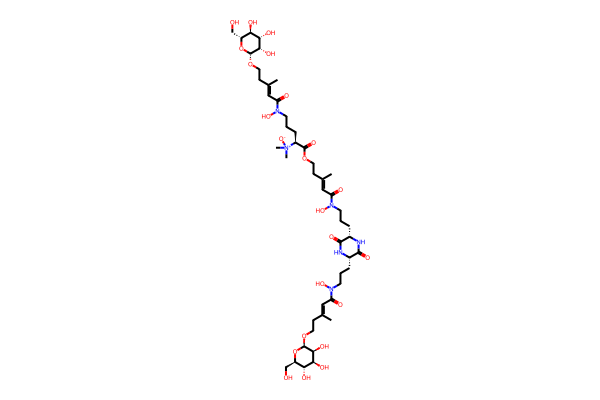

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…

In [191]:
beau = Chem.MolFromSmiles('C/C(=C\C(=O)N(CCC[C@H]1C(=O)N[C@H](C(=O)N1)CCCN(C(=O)/C=C(\C)/CCOC(=O)[C@H](CCCN(C(=O)/C=C(\C)/CCO[C@H]2[C@H]([C@H]([C@@H]([C@H](O2)CO)O)O)O)O)[N+](C)(C)[O-])O)O)/CCO[C@H]3[C@H]([C@H]([C@@H]([C@H](O3)CO)O)O)O')
display(beau)

geass = Geass()
prods = geass.get_fragments(beau)
geass.show_connection_graph()

# Fragment C/C(=C\C(=O)O)CCO  >  LTS0069744: (2e)-5-hydroxy-3-methylpent-2-enoic acid

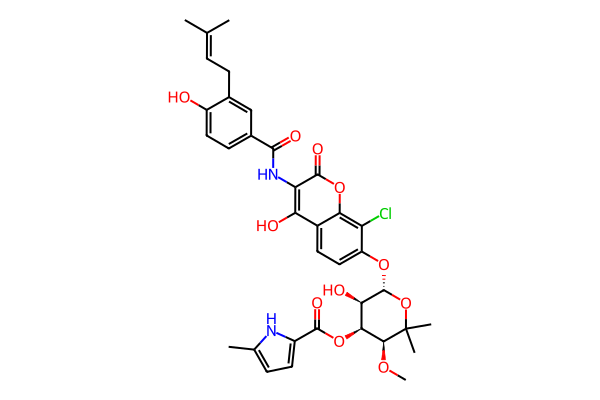

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…

In [193]:
fora = Chem.MolFromSmiles('CO[C@H]1[C@@H](OC(=O)c2ccc(C)[nH]2)[C@@H](O)[C@H](Oc2ccc3c(O)c(NC(=O)c4ccc(O)c(CC=C(C)C)c4)c(=O)oc3c2Cl)OC1(C)C')
display(fora)

geass = Geass()
prods = geass.get_fragments(fora)
geass.show_connection_graph()

## Visualise NP Atlas chemical space